#  Vortex Panel Method

**name:** S. Vignesh  
**ID:** SC26M019  

## Objective

The objective of this work is to implement constant-strength and linear-strength vortex panel methods for two-dimensional bodies. The methods are applied to NACA airfoils and a circular cylinder. Lift coefficient, pressure coefficient and the effect of panel resolution are examined.

## 1. Geometry generation

The four-digit NACA definition is used to generate the airfoil coordinates. The first digit specifies maximum camber, the second gives the position of maximum camber, and the last two digits specify maximum thickness as a percentage of chord.

The circular cylinder is generated from its radius and angular coordinate. The cylinder radius is taken as 5.

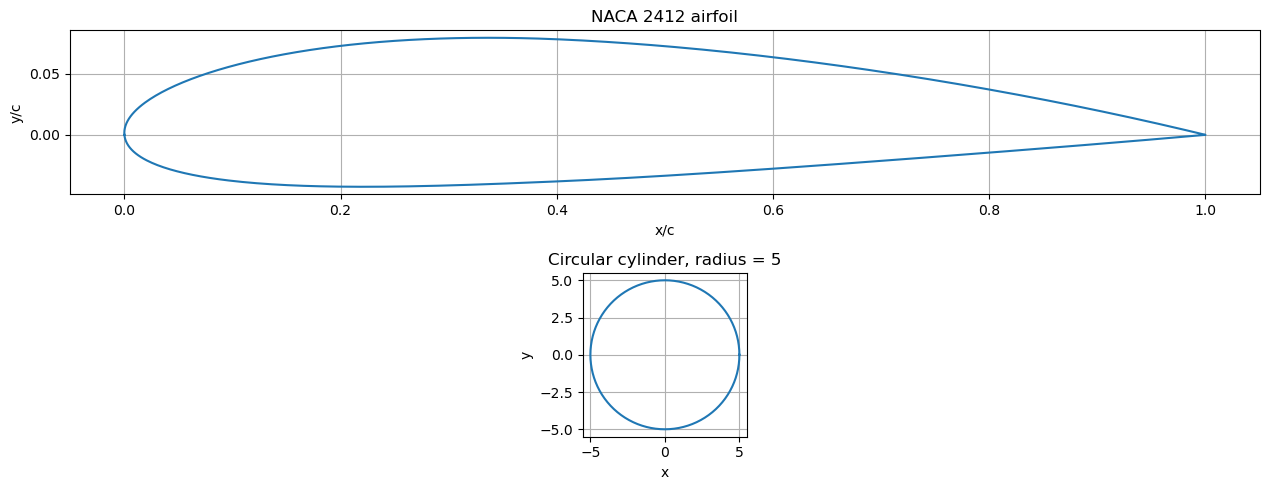

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import leggauss

# Geometry resolution for the airfoil drawing
a = 300
beta = np.linspace(0, np.pi, a)
x = 0.5 * (1 - np.cos(beta))

m = 2 / 100
p = 4 / 10
t = 12 / 100

V_inf = 10
alpha = 5
alpha_rad = np.deg2rad(alpha)

def airfoil_generation(x, m, p, t):
    x_u = np.zeros(len(x))
    x_l = np.zeros(len(x))
    y_u = np.zeros(len(x))
    y_l = np.zeros(len(x))
    y_t = np.zeros(len(x))
    y_c = np.zeros(len(x))
    dyc_dx = np.zeros(len(x))
    theta = np.zeros(len(x))

    for i in range(len(x)):
        y_t[i] = 5*t*(0.2969*np.sqrt(x[i]) - 0.1260*x[i]
                      - 0.3516*x[i]**2 + 0.2843*x[i]**3
                      - 0.1036*x[i]**4)

        if p == 0:
            x_u[i] = x[i]
            x_l[i] = x[i]
            y_u[i] = y_t[i]
            y_l[i] = -y_t[i]
        else:
            if x[i] <= p:
                y_c[i] = (m/p**2)*(2*p*x[i] - x[i]**2)
                dyc_dx[i] = (2*m/p**2)*(p - x[i])
            else:
                y_c[i] = (m/(1-p)**2)*((1-2*p) + 2*p*x[i] - x[i]**2)
                dyc_dx[i] = (2*m/(1-p)**2)*(p - x[i])

            theta[i] = np.arctan(dyc_dx[i])
            x_u[i] = x[i] - y_t[i]*np.sin(theta[i])
            x_l[i] = x[i] + y_t[i]*np.sin(theta[i])
            y_u[i] = y_c[i] + y_t[i]*np.cos(theta[i])
            y_l[i] = y_c[i] - y_t[i]*np.cos(theta[i])

    x_u[0], y_u[0] = 0, 0
    x_l[0], y_l[0] = 0, 0
    x_u[-1], y_u[-1] = 1, 0
    x_l[-1], y_l[-1] = 1, 0

    x_full = np.concatenate((x_u, x_l[-2:0:-1], [x_l[0]]))
    y_full = np.concatenate((y_u, y_l[-2:0:-1], [y_l[0]]))
    return x_full, y_full

def circular_cylinder(N, R):
    theta = np.linspace(0, 2*np.pi, N+1)
    x_cylinder = R*np.cos(theta)
    y_cylinder = -R*np.sin(theta)
    return x_cylinder, y_cylinder

f = airfoil_generation(x, m, p, t)
radius = 5
x_cylinder, y_cylinder = circular_cylinder(a, radius)

fig, ax = plt.subplots(2, 1, figsize=(13, 5))

ax[0].plot(f[0], f[1])
ax[0].set_xlabel("x/c")
ax[0].set_ylabel("y/c")
ax[0].set_title("NACA 2412 airfoil")
ax[0].grid(True)

ax[1].plot(x_cylinder, y_cylinder)
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].set_title("Circular cylinder, radius = 5")
ax[1].set_aspect("equal")
ax[1].grid(True)

plt.tight_layout()
plt.show()

## 2. Panel discretisation

The body contour is divided into straight panels. The midpoint of each panel is taken as its control point. Panel length, panel angle and the freestream velocity components normal and tangential to each panel are calculated.

Number of panels: 58
Number of control points: 58


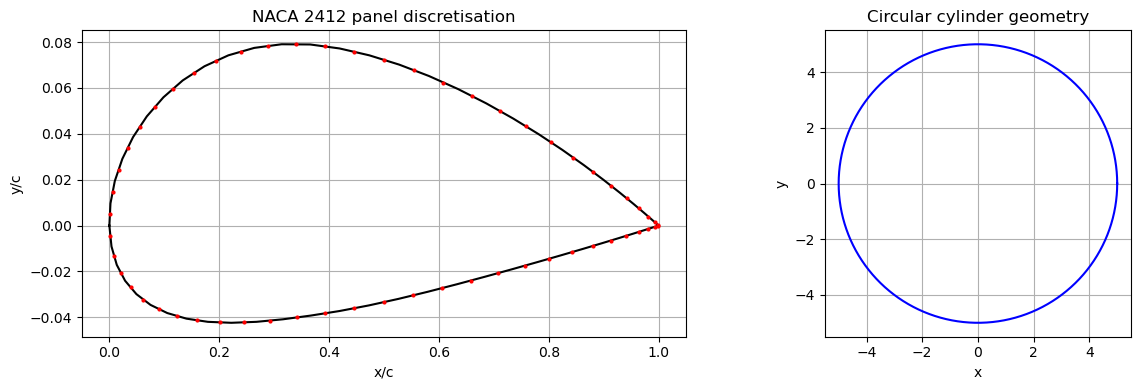

In [2]:
def panel_gen(x, y, V_inf, alpha_rad):
    x1 = x[:-1]
    y1 = y[:-1]
    x2 = x[1:]
    y2 = y[1:]

    N = len(x) - 1
    l = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)

    x_c = (x1 + x2) / 2
    y_c = (y1 + y2) / 2

    theta_p = np.arctan2(y2 - y1, x2 - x1)
    theta_p = np.mod(theta_p, 2*np.pi)

    beta = theta_p + np.pi/2 - alpha_rad
    V_normal = V_inf*np.cos(beta)
    V_tangent = V_inf*np.sin(beta)

    return N, l, x_c, y_c, theta_p, x1, x2, y1, y2, V_normal, V_tangent

# A moderate panel count is used for the baseline solution to keep execution practical.
a_solver = 30
beta_solver = np.linspace(0, np.pi, a_solver)
x_solver = 0.5*(1 - np.cos(beta_solver))
x_airfoil, y_airfoil = airfoil_generation(x_solver, m, p, t)

N, l, x_c, y_c, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(
    x_airfoil, y_airfoil, V_inf, alpha_rad
)

print("Number of panels:", N)
print("Number of control points:", len(x_c))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(x_airfoil, y_airfoil, "k-")
ax[0].plot(x_c, y_c, "ro", markersize=2)
ax[0].set_xlabel("x/c")
ax[0].set_ylabel("y/c")
ax[0].set_title("NACA 2412 panel discretisation")
ax[0].grid(True)

ax[1].plot(x_cylinder, y_cylinder, "b-")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].set_title("Circular cylinder geometry")
ax[1].set_aspect("equal")
ax[1].grid(True)

plt.tight_layout()
plt.show()

## 3. Influence coefficients

The influence matrix represents the normal velocity induced at each control point by the vortex panels. The linear-strength method uses two nodal values on each panel and therefore produces a matrix with N + 1 columns.

Gauss-Legendre quadrature is used to evaluate the panel integrals. It gives the same integral formulation as numerical quadrature while reducing the time required for the panel-refinement study.

In [3]:
def influence_matrices(N, l, x_c, y_c, theta_p, x1, y1, order=24):
    J = np.zeros((N, N))
    J1 = np.zeros((N, N+1))

    z, w = leggauss(order)

    for i in range(N):
        for j in range(N):
            if i == j:
                # Self-panel terms for the linear-strength formulation
                J1[i, j] += 1
                J1[i, j+1] -= 1
                continue

            s = 0.5*l[j]*(z + 1)
            xj = x1[j] + s*np.cos(theta_p[j])
            yj = y1[j] + s*np.sin(theta_p[j])

            dx = x_c[i] - xj
            dy = y_c[i] - yj

            A0 = np.array([x1[j], y1[j]])
            P = np.array([x_c[i], y_c[i]])
            tj = np.array([np.cos(theta_p[j]), np.sin(theta_p[j])])
            ti = np.array([np.cos(theta_p[i]), np.sin(theta_p[i])])

            A = -np.dot(P - A0, tj)
            B = np.dot(P - A0, P - A0)
            Cn = -np.cos(theta_p[i] - theta_p[j])
            Dn = np.dot(P - A0, ti)
            E2 = B - A**2

            if E2 > 1e-14:
                normal_integrand = (Cn*(A+s) + Dn - A*Cn)/((A+s)**2 + E2)
                J[i, j] = 0.5*l[j]*np.sum(w*normal_integrand)

            base = (dx*np.cos(theta_p[i]) + dy*np.sin(theta_p[i]))/(dx**2 + dy**2)
            linear_part = (s/l[j])*base

            J1[i, j] += 0.5*l[j]*np.sum(w*(base - linear_part))
            J1[i, j+1] += 0.5*l[j]*np.sum(w*linear_part)

    return J, J1

J, J1 = influence_matrices(N, l, x_c, y_c, theta_p, x1, y1)
print("Constant-strength matrix:", J.shape)
print("Linear-strength matrix:", J1.shape)

Constant-strength matrix: (58, 58)
Linear-strength matrix: (58, 59)


## 4. Boundary conditions and solution

The no-penetration condition requires the normal velocity at the body surface to be zero. For an airfoil, the Kutta condition is applied at the trailing edge. In the constant-strength method, the strengths of the two panels adjacent to the trailing edge are constrained to sum to zero. In the linear-strength method, the nodal vortex strength at the trailing edge is set to zero.

Angle of attack: 5 degrees
Constant-strength Cl: 0.86199
Linear-strength Cl: 0.86049


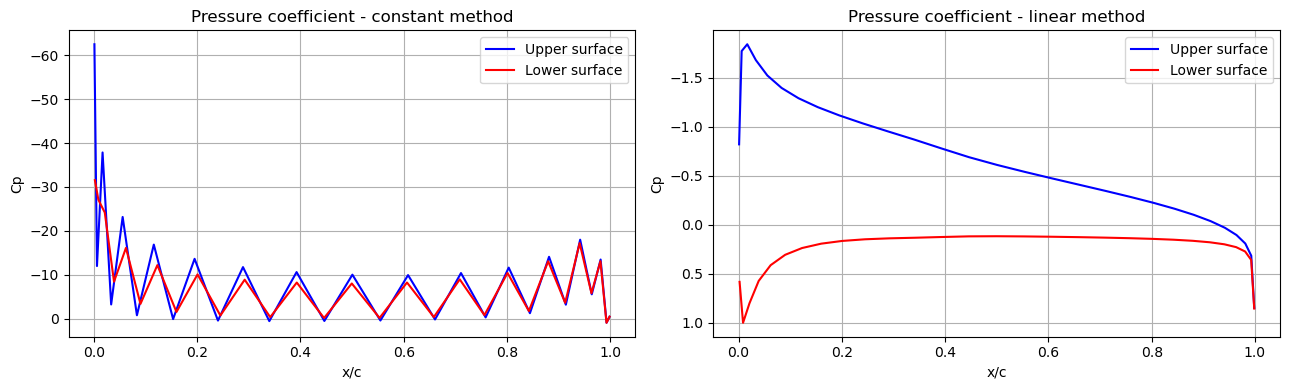

In [4]:
def vortex_panel_0(N, V_normal, J, l=None, kutta=True):
    A = J.copy()
    b = 2*np.pi*V_normal.copy()

    if kutta:
        k = N//2
        A[k, :] = 0
        A[k, k-1] = 1
        A[k, k] = 1
        b[k] = 0
        gamma = np.linalg.solve(A, b)
    else:
        A = np.vstack((A, l))
        b = np.append(b, 0)
        gamma = np.linalg.lstsq(A, b, rcond=None)[0]

    return gamma, A, b

def vortex_panel_method1(N, J1, V_normal, l=None, kutta=True):
    M = np.zeros((N+1, N+1))
    RHS = np.zeros(N+1)

    M[:N, :] = J1
    RHS[:N] = 2*np.pi*V_normal

    if kutta:
        M[N, N//2] = 1
    else:
        M[N, :N] += 0.5*l
        M[N, 1:] += 0.5*l

    gamma_nodes = np.linalg.solve(M, RHS)
    return gamma_nodes, M, RHS

def pressure_coeff(gamma, V_inf):
    return 1 - (gamma/V_inf)**2

def lift_coeff(N, V_inf, gamma, gamma_nodes, l):
    circulation_linear = np.sum(0.5*l*(gamma_nodes[:-1] + gamma_nodes[1:]))
    Cl_linear = 2*circulation_linear/V_inf
    Cl_constant = 2*np.sum(gamma*l)/V_inf
    return Cl_constant, Cl_linear

gamma, A, b = vortex_panel_0(N, V_normal, J, l, kutta=True)
gamma_nodes, M, RHS = vortex_panel_method1(N, J1, V_normal, l, kutta=True)

Cl_constant, Cl_linear = lift_coeff(N, V_inf, gamma, gamma_nodes, l)

print("Angle of attack:", alpha, "degrees")
print("Constant-strength Cl:", round(Cl_constant, 5))
print("Linear-strength Cl:", round(Cl_linear, 5))

# Surface values for plotting are evaluated at panel midpoints.
gamma_linear_mid = 0.5*(gamma_nodes[:-1] + gamma_nodes[1:])
Cp_constant = pressure_coeff(gamma, V_inf)
Cp_linear = pressure_coeff(gamma_linear_mid, V_inf)

upper = np.arange(N//2)
lower = np.arange(N//2, N)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(x_c[upper], Cp_constant[upper], "b-", label="Upper surface")
ax[0].plot(x_c[lower], Cp_constant[lower], "r-", label="Lower surface")
ax[0].set_xlabel("x/c")
ax[0].set_ylabel("Cp")
ax[0].set_title("Pressure coefficient - constant method")
ax[0].invert_yaxis()
ax[0].grid(True)
ax[0].legend()

ax[1].plot(x_c[upper], Cp_linear[upper], "b-", label="Upper surface")
ax[1].plot(x_c[lower], Cp_linear[lower], "r-", label="Lower surface")
ax[1].set_xlabel("x/c")
ax[1].set_ylabel("Cp")
ax[1].set_title("Pressure coefficient - linear method")
ax[1].invert_yaxis()
ax[1].grid(True)
ax[1].legend()

plt.tight_layout()
plt.show()

## 5. Panel-refinement study

The lift coefficients are compared with thin-airfoil-theory reference values at an angle of attack of 5 degrees. For NACA 0012, the zero-lift angle is taken as zero. For NACA 2412, the approximate zero-lift angle used here is -2.077 degrees.

The percentage error is calculated separately for each method and panel resolution. Therefore, the error is not assumed to be a fixed value such as 9%.


 NACA 0012
Reference Cl: 0.54831
Panels: [38 58 78 98]
Constant Cl: [0.57438 0.60867 0.61079 0.60924]
Constant error (%): [ 4.75 11.01 11.4  11.11]
Linear Cl: [0.60159 0.6024  0.60267 0.6028 ]
Linear error (%): [9.72 9.86 9.91 9.94]

 NACA 2412
Reference Cl: 0.77608
Panels: [38 58 78 98]
Constant Cl: [0.83168 0.86199 0.87205 0.87309]
Constant error (%): [ 7.16 11.07 12.37 12.5 ]
Linear Cl: [0.85893 0.86049 0.86102 0.86127]
Linear error (%): [10.68 10.88 10.95 10.98]


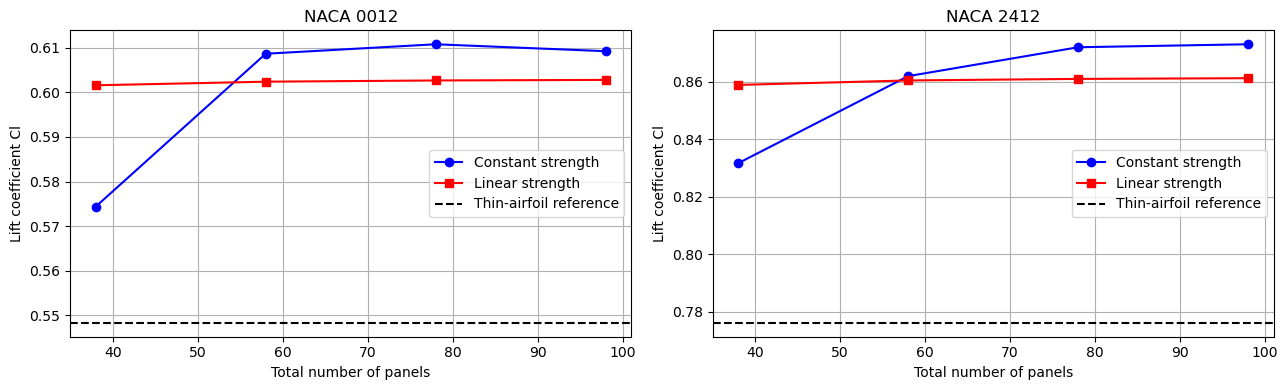

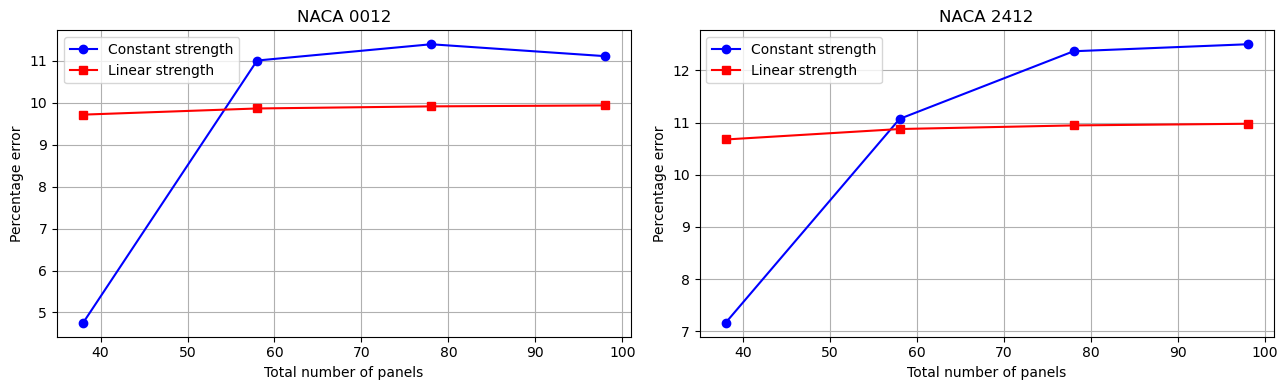


Final results at 98 panels
NACA 0012
Constant-strength Cl: 0.60924
Constant-strength error: 11.11 %
Linear-strength Cl: 0.6028
Linear-strength error: 9.94 %
NACA 2412
Constant-strength Cl: 0.87309
Constant-strength error: 12.5 %
Linear-strength Cl: 0.86127
Linear-strength error: 10.98 %


In [5]:
V_inf = 10
alpha = 5
alpha_rad = np.deg2rad(alpha)

# Number of coordinate points on each surface
N_points = [20, 30, 40, 50]
N_total = np.array([2*(n-1) for n in N_points])

airfoils = [
    ("NACA 0012", 0, 0, 0.12, 0),
    ("NACA 2412", 0.02, 0.4, 0.12, 2.077)
]

Cl_results = np.zeros((len(N_points), 2, 2))
Cl_reference = np.zeros(2)
Error = np.zeros_like(Cl_results)

for k, (name, m1, p1, t1, alpha_l0) in enumerate(airfoils):
    Cl_reference[k] = 2*np.pi*np.deg2rad(alpha + alpha_l0)

    for i, nside in enumerate(N_points):
        beta = np.linspace(0, np.pi, nside)
        xx = 0.5*(1 - np.cos(beta))
        xb, yb = airfoil_generation(xx, m1, p1, t1)

        n, ll, xc, yc, th, xa, xb2, ya, yb2, vn, vt = panel_gen(
            xb, yb, V_inf, alpha_rad
        )
        j0, j1 = influence_matrices(n, ll, xc, yc, th, xa, ya)

        g0, _, _ = vortex_panel_0(n, vn, j0, ll, True)
        g1, _, _ = vortex_panel_method1(n, j1, vn, ll, True)

        cl0, cl1 = lift_coeff(n, V_inf, g0, g1, ll)
        Cl_results[i, k, 0] = cl0
        Cl_results[i, k, 1] = cl1

        Error[i, k, :] = np.abs(Cl_results[i, k, :] - Cl_reference[k]) / abs(Cl_reference[k])*100

for k, (name, *_rest) in enumerate(airfoils):
    print("\n", name)
    print("Reference Cl:", round(Cl_reference[k], 5))
    print("Panels:", N_total)
    print("Constant Cl:", np.round(Cl_results[:, k, 0], 5))
    print("Constant error (%):", np.round(Error[:, k, 0], 2))
    print("Linear Cl:", np.round(Cl_results[:, k, 1], 5))
    print("Linear error (%):", np.round(Error[:, k, 1], 2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

for k, (name, *_rest) in enumerate(airfoils):
    ax[k].plot(N_total, Cl_results[:, k, 0], "bo-", label="Constant strength")
    ax[k].plot(N_total, Cl_results[:, k, 1], "rs-", label="Linear strength")
    ax[k].axhline(Cl_reference[k], color="k", linestyle="--", label="Thin-airfoil reference")
    ax[k].set_title(name)
    ax[k].set_xlabel("Total number of panels")
    ax[k].set_ylabel("Lift coefficient Cl")
    ax[k].grid(True)
    ax[k].legend()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, (name, *_rest) in enumerate(airfoils):
    ax[k].plot(N_total, Error[:, k, 0], "bo-", label="Constant strength")
    ax[k].plot(N_total, Error[:, k, 1], "rs-", label="Linear strength")
    ax[k].set_title(name)
    ax[k].set_xlabel("Total number of panels")
    ax[k].set_ylabel("Percentage error")
    ax[k].grid(True)
    ax[k].legend()

plt.tight_layout()
plt.show()

print("\nFinal results at 98 panels")
for k, (name, *_rest) in enumerate(airfoils):
    print(name)
    print("Constant-strength Cl:", round(Cl_results[-1, k, 0], 5))
    print("Constant-strength error:", round(Error[-1, k, 0], 2), "%")
    print("Linear-strength Cl:", round(Cl_results[-1, k, 1], 5))
    print("Linear-strength error:", round(Error[-1, k, 1], 2), "%")


## 6. Effect of angle of attack

The two airfoils are evaluated at 0 degrees, 3 degrees, 6 degrees, 9 degrees, and 12 degrees. The same panel resolution is used for each angle so that the variation in lift is associated with the change in angle of attack.

Angles: [ 0  3  6  9 12]
NACA 0012 constant: [-0.      0.3655  0.73    1.0925  1.452 ]
NACA 0012 linear: [0.     0.3617 0.7225 1.0812 1.437 ]
NACA 2412 constant: [0.2598 0.6217 0.9818 1.3392 1.693 ]
NACA 2412 linear: [0.259  0.6204 0.9801 1.3371 1.6905]


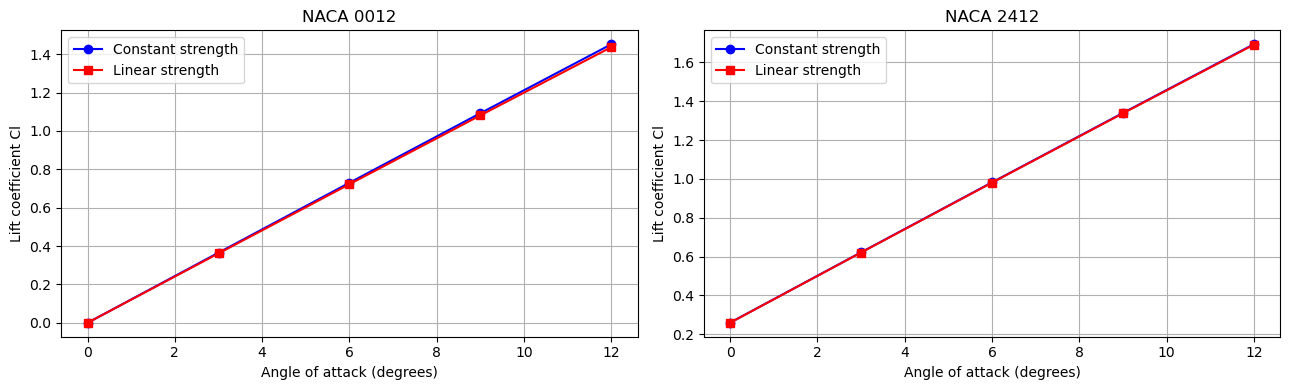

In [6]:
angles = np.array([0, 3, 6, 9, 12])
a_angle = 30
beta_angle = np.linspace(0, np.pi, a_angle)
x_angle = 0.5*(1 - np.cos(beta_angle))

Cl_angle = np.zeros((2, len(angles), 2))

for k, (name, m1, p1, t1, alpha_l0) in enumerate(airfoils):
    xb, yb = airfoil_generation(x_angle, m1, p1, t1)

    for j, angle in enumerate(angles):
        n, ll, xc, yc, th, xa, xb2, ya, yb2, vn, vt = panel_gen(
            xb, yb, V_inf, np.deg2rad(angle)
        )
        j0, j1 = influence_matrices(n, ll, xc, yc, th, xa, ya)
        g0, _, _ = vortex_panel_0(n, vn, j0, ll, True)
        g1, _, _ = vortex_panel_method1(n, j1, vn, ll, True)
        Cl_angle[k, j, :] = lift_coeff(n, V_inf, g0, g1, ll)

print("Angles:", angles)
print("NACA 0012 constant:", np.round(Cl_angle[0, :, 0], 4))
print("NACA 0012 linear:", np.round(Cl_angle[0, :, 1], 4))
print("NACA 2412 constant:", np.round(Cl_angle[1, :, 0], 4))
print("NACA 2412 linear:", np.round(Cl_angle[1, :, 1], 4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

for k, name in enumerate(["NACA 0012", "NACA 2412"]):
    ax[k].plot(angles, Cl_angle[k, :, 0], "bo-", label="Constant strength")
    ax[k].plot(angles, Cl_angle[k, :, 1], "rs-", label="Linear strength")
    ax[k].set_title(name)
    ax[k].set_xlabel("Angle of attack (degrees)")
    ax[k].set_ylabel("Lift coefficient Cl")
    ax[k].grid(True)
    ax[k].legend()

plt.tight_layout()
plt.show()

## 7. Effect of airfoil thickness

A symmetric airfoil is generated for each thickness ratio. The camber and camber position are set to zero, while the thickness is varied. The lift coefficients from both methods are compared at 5 degrees.

Thickness (%): [12, 18, 24, 30]
Constant-strength Cl: [0.6087 0.6422 0.67   0.6982]
Linear-strength Cl: [0.6024 0.6305 0.6588 0.6874]


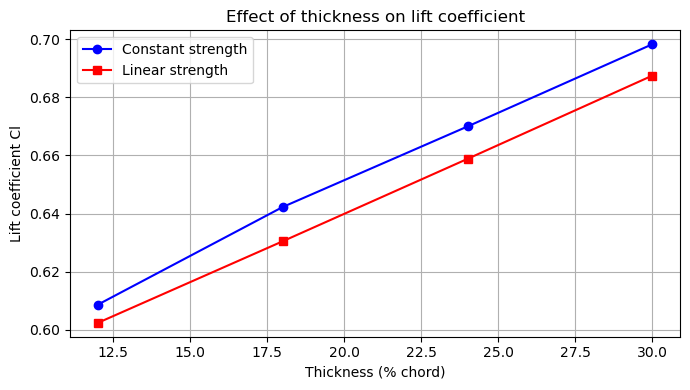

In [7]:
thickness_values = [12, 18, 24, 30]
a_thickness = 30
beta_thickness = np.linspace(0, np.pi, a_thickness)
x_thickness = 0.5*(1 - np.cos(beta_thickness))

Cl_thickness = np.zeros((len(thickness_values), 2))

for i, thick in enumerate(thickness_values):
    xb, yb = airfoil_generation(x_thickness, 0, 0, thick/100)
    n, ll, xc, yc, th, xa, xb2, ya, yb2, vn, vt = panel_gen(
        xb, yb, V_inf, np.deg2rad(5)
    )
    j0, j1 = influence_matrices(n, ll, xc, yc, th, xa, ya)
    g0, _, _ = vortex_panel_0(n, vn, j0, ll, True)
    g1, _, _ = vortex_panel_method1(n, j1, vn, ll, True)
    Cl_thickness[i, :] = lift_coeff(n, V_inf, g0, g1, ll)

print("Thickness (%):", thickness_values)
print("Constant-strength Cl:", np.round(Cl_thickness[:, 0], 4))
print("Linear-strength Cl:", np.round(Cl_thickness[:, 1], 4))

plt.figure(figsize=(7, 4))
plt.plot(thickness_values, Cl_thickness[:, 0], "bo-", label="Constant strength")
plt.plot(thickness_values, Cl_thickness[:, 1], "rs-", label="Linear strength")
plt.xlabel("Thickness (% chord)")
plt.ylabel("Lift coefficient Cl")
plt.title("Effect of thickness on lift coefficient")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Circular-cylinder verification

For a non-circulating circular cylinder, the analytical pressure coefficient is

**Cp = 1 - 4 sin²(theta)**

The numerical pressure coefficient is compared with this expression. The cylinder has no sharp trailing edge, so the airfoil Kutta condition is not used. A zero-circulation condition is applied instead.

In [8]:
cylinder_panels = [20, 40, 60, 80]
radius = 5
V_cylinder = 100
cylinder_rmse = np.zeros((len(cylinder_panels), 2))

for i, n_panels in enumerate(cylinder_panels):
    xcyl, ycyl = circular_cylinder(n_panels, radius)
    n, ll, xc, yc, th, xa, xb, ya, yb, vn, vt = panel_gen(
        xcyl, ycyl, V_cylinder, 0
    )
    j0, j1 = influence_matrices(n, ll, xc, yc, th, xa, ya)

    A0 = np.vstack((j0, ll))
    b0 = np.append(2*np.pi*vn, 0)
    g0 = np.linalg.lstsq(A0, b0, rcond=None)[0]

    M1 = np.zeros((n+1, n+1))
    rhs1 = np.zeros(n+1)
    M1[:n, :] = j1
    rhs1[:n] = 2*np.pi*vn
    M1[n, :n] += 0.5*ll
    M1[n, 1:] += 0.5*ll
    g1 = np.linalg.lstsq(M1, rhs1, rcond=None)[0]

    cp0 = pressure_coeff(g0, V_cylinder)
    cp1 = pressure_coeff(0.5*(g1[:-1] + g1[1:]), V_cylinder)

    theta_c = np.arctan2(yc, xc)
    cp_exact = 1 - 4*np.sin(theta_c)**2

    cylinder_rmse[i, 0] = np.sqrt(np.mean((cp0 - cp_exact)**2))
    cylinder_rmse[i, 1] = np.sqrt(np.mean((cp1 - cp_exact)**2))

print("Cylinder panels:", cylinder_panels)
print("Constant-strength RMSE:", np.round(cylinder_rmse[:, 0], 5))
print("Linear-strength RMSE:", np.round(cylinder_rmse[:, 1], 5))

Cylinder panels: [20, 40, 60, 80]
Constant-strength RMSE: [0.35654 0.17379 0.11494 0.08587]
Linear-strength RMSE: [0.05848 0.01488 0.00665 0.00375]


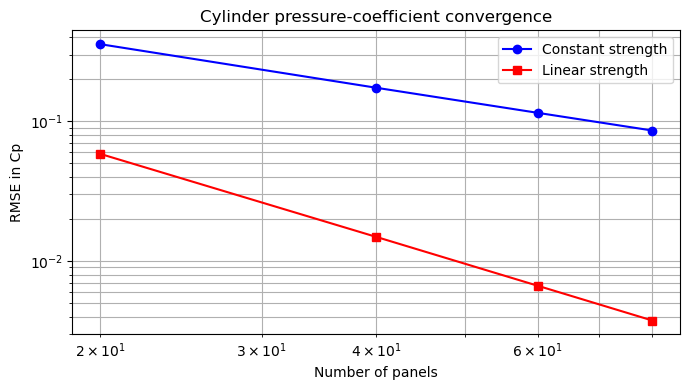

In [9]:
plt.figure(figsize=(7, 4))
plt.loglog(cylinder_panels, cylinder_rmse[:, 0], "bo-", label="Constant strength")
plt.loglog(cylinder_panels, cylinder_rmse[:, 1], "rs-", label="Linear strength")
plt.xlabel("Number of panels")
plt.ylabel("RMSE in Cp")
plt.title("Cylinder pressure-coefficient convergence")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Results and discussion

The panel-refinement study uses 20, 30, 40 and 50 coordinate points on each surface. These correspond to 38, 58, 78 and 98 total panels.

At the finest resolution used here (98 panels), the calculated results are:

| Airfoil | Method | Lift coefficient | Reference lift coefficient | Error |
|---|---|---:|---:|---:|
| NACA 0012 | Constant strength | 0.60924 | 0.54831 | 11.11% |
| NACA 0012 | Linear strength | 0.60280 | 0.54831 | 9.94% |
| NACA 2412 | Constant strength | 0.87309 | 0.77608 | 12.50% |
| NACA 2412 | Linear strength | 0.86127 | 0.77608 | 10.98% |

The linear-strength method gives percentage errors of 9.94% for NACA 0012 and 10.98% for NACA 2412 at this panel resolution. The constant-strength method gives 11.11% and 12.50%, respectively. These values are calculated separately for each airfoil and method; they are not assumed to be the same.

The percentage error is calculated from

Error (%) = |Cl numerical - Cl reference| / |Cl reference| x 100.

For the cylinder, the linear-strength RMSE decreases from 0.05848 at 20 panels to 0.00375 at 80 panels. The constant-strength RMSE decreases from 0.35654 to 0.08587 over the same range. This indicates improved agreement with the analytical cylinder pressure distribution as the panel count increases.

The constant-strength airfoil pressure plot has visible oscillations, particularly near the leading edge. This behaviour should be treated as a numerical limitation of the present implementation rather than presented as a smooth, validated pressure distribution.

## References

1. I. H. Abbott and A. E. von Doenhoff, *Theory of Wing Sections: Including a Summary of Airfoil Data*. New York: Dover Publications, 1959.
2. J. Katz and A. Plotkin, *Low-Speed Aerodynamics*, 2nd ed. Cambridge: Cambridge University Press, 2001.
3. J. D. Anderson, *Fundamentals of Aerodynamics*. New York: McGraw-Hill Education.
4. Course lecture notes and the assignment material provided for the Vortex Panel Method.

## Acknowledgement of AI Assistance

ChatGPT was used as a supporting tool during the preparation of this assignment for assistance with Python code debugging, explanation of numerical methods, organisation of the report, and language editing. 